In [19]:
import sys
sys.path.append('/home/pavel/pyadi-iio/')
import adi
import time
import matplotlib.pyplot as plt
import numpy as np
import scipy
import numpy.matlib

In [20]:
sample_rate = 1e6 # Hz
center_freq = 2e9 # Hz
num_samps = 10000 # number of samples returned per call to rx()

sdr_rx = adi.Pluto('ip:192.168.2.1')
# sdr_tx = adi.Pluto('ip:192.168.2.2')


In [21]:
sdr_rx.rx_lo = int(center_freq)
sdr_rx.gain_control_mode_chan0 = 'manual'
sdr_rx.rx_hardwaregain_chan0 = 70.0 # dB
sdr_rx.sample_rate = int(sample_rate)
sdr_rx.rx_rf_bandwidth = int(sample_rate) # filter width, just set it to the same as sample rate for now
sdr_rx.rx_buffer_size = num_samps

samples = sdr_rx.rx() # receive samples off Pluto
print(samples[0:10])

[ 20. -1.j  -7. +8.j -18.+10.j -28.+40.j   3.+24.j  34.-51.j   9.+48.j
 -23.+85.j   7.+29.j  -6.+73.j]


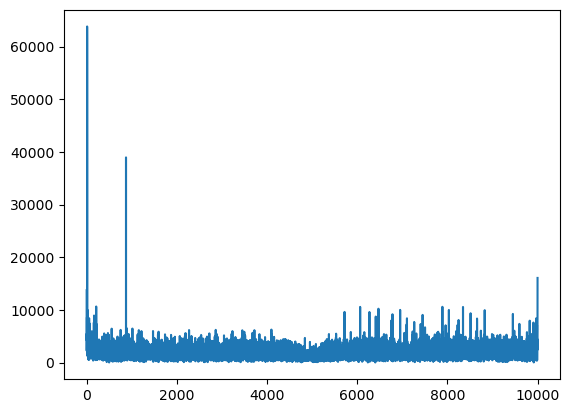

In [22]:
plt.plot(np.abs(np.fft.fft(samples)))

In [23]:
sdr_tx = adi.Pluto('ip:192.168.2.2')

Exception: No device found